# Learning Matplotlib and Seaborn - Part 2

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

### Scatterplots

#### Matplot

      id        make           model  year           VClass  \
0  32204      Nissan            GT-R  2013  Subcompact Cars   
1  32205  Volkswagen              CC  2013     Compact Cars   
2  32206  Volkswagen              CC  2013     Compact Cars   
3  32207  Volkswagen      CC 4motion  2013     Compact Cars   
4  32208   Chevrolet  Malibu eAssist  2013     Midsize Cars   

               drive              trans          fuelType  cylinders  displ  \
0    All-Wheel Drive    Automatic (AM6)  Premium Gasoline          6    3.8   
1  Front-Wheel Drive  Automatic (AM-S6)  Premium Gasoline          4    2.0   
2  Front-Wheel Drive     Automatic (S6)  Premium Gasoline          6    3.6   
3    All-Wheel Drive     Automatic (S6)  Premium Gasoline          6    3.6   
4  Front-Wheel Drive     Automatic (S6)  Regular Gasoline          4    2.4   

   pv2  pv4     city    UCity  highway  UHighway     comb  co2  feScore  \
0   79    0  16.4596  20.2988  22.5568   30.1798  18.7389  471        4

Text(0, 0.5, 'Combned Fuel Eff (mpg)')

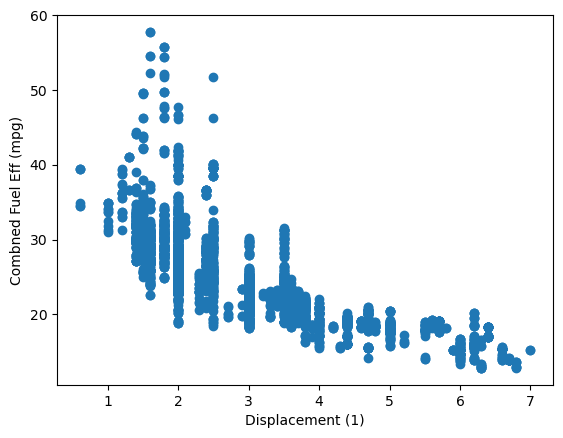

In [ ]:
fuel_econ = pd.read_csv('./data/csvs/fuel-econ.csv')
print(fuel_econ.head())

plt.scatter(data=fuel_econ, x='displ', y='comb');

plt.xlabel('Displacement (1)')
plt.ylabel('Combned Fuel Eff (mpg)')

#### Seaborn

Text(0, 0.5, 'Combined Fuel Eff. (mpg)')

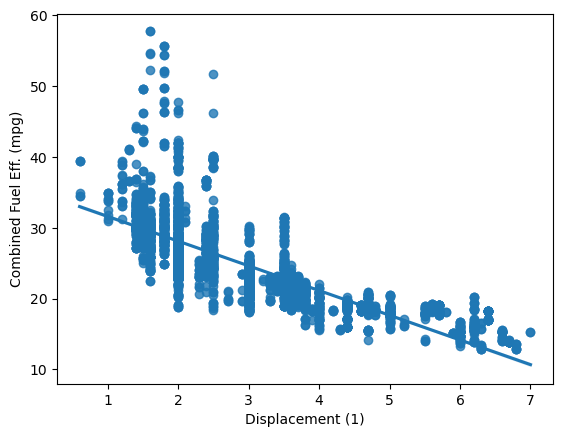

In [42]:
sb.regplot(data=fuel_econ, x='displ', y='comb');
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

Scatter plot showing a positive correlation between two variables

Text(0, 0.5, 'Combined Fuel Eff. (mpg)')

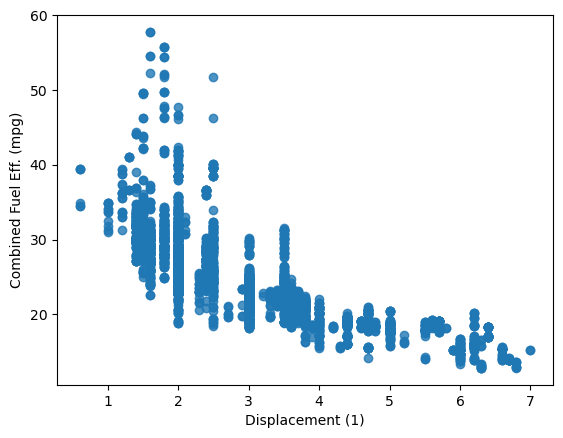

In [43]:
sb.regplot(data=fuel_econ, x='displ', y='comb', fit_reg=False);
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

Plot the regression line on the transformed data

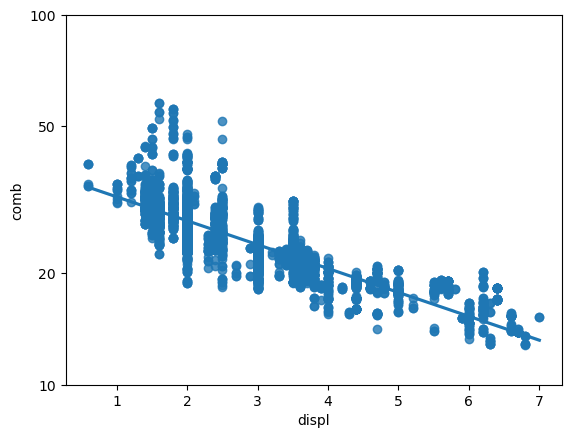

In [44]:
def log_trans(x, inverse=False):
    if not inverse:
        return np.log10(x)
    else:
        return np.power(10, x)

sb.regplot(data=fuel_econ, x=fuel_econ['displ'], y=fuel_econ['comb'].apply(log_trans))
tick_locs = [10, 20, 50, 100]
plt.yticks(log_trans(tick_locs), tick_locs);

#### Overplotting, Transparency, and Jitter

Jitter

<Axes: xlabel='year', ylabel='comb'>

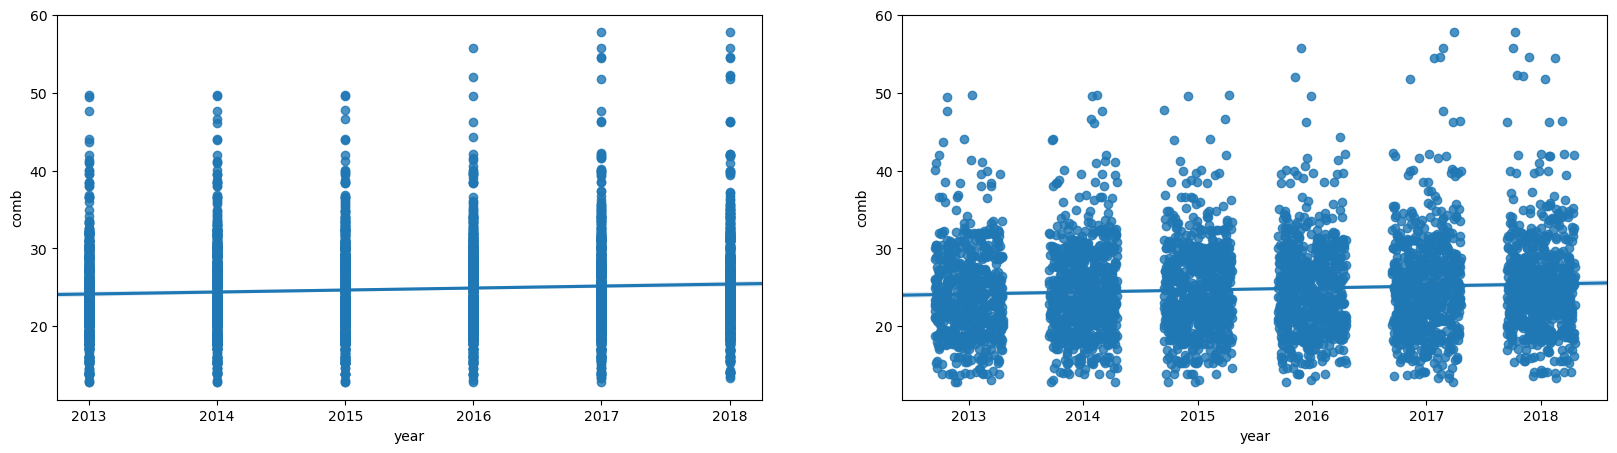

In [45]:
plt.figure(figsize = [20,5])

plt.subplot(1,2,1)
sb.regplot(data=fuel_econ, x='year', y='comb', truncate=False)

plt.subplot(1,2,2)
sb.regplot(data=fuel_econ, x='year', y='comb', truncate=False, x_jitter=0.3)

Jitter and transparency

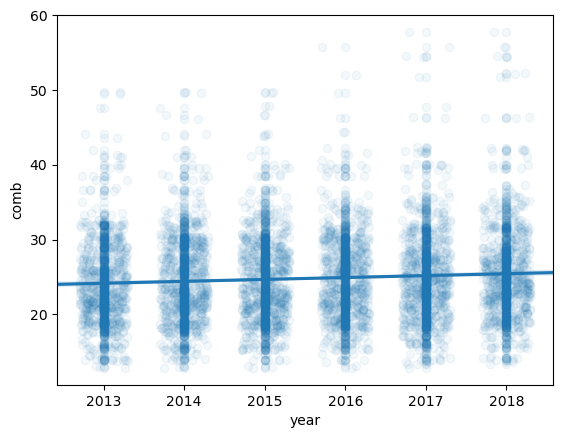

In [46]:
# plt.figure(figsize = [20,5])


# plt.subplot(1,2,1)
sb.regplot(data=fuel_econ, x='year', y='comb', truncate=False, x_jitter=0.3, scatter_kws={'alpha': 1/20})

# plt.subplot(1,2,2)
plt.scatter(data=fuel_econ, x='year', y='comb', alpha=1/20)


#### Heatmaps

Text(0, 0.5, 'Combined Fuel Eff. (mpg)')

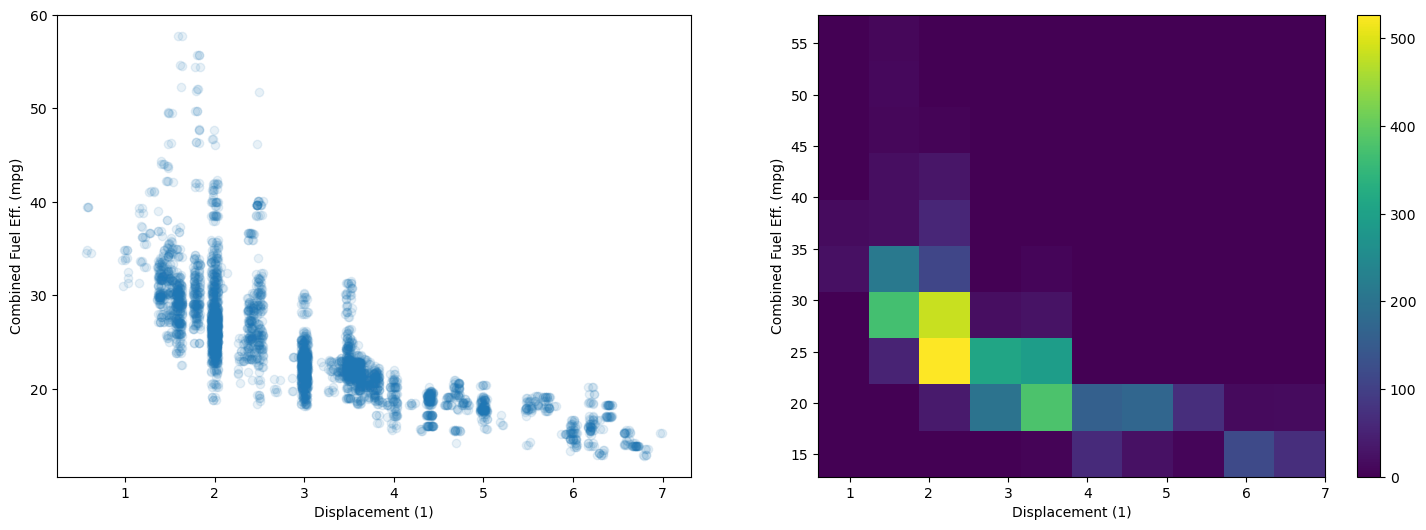

In [ ]:
plt.figure(figsize=[18,6])

plt.subplot(1,2,1)
sb.regplot(data=fuel_econ, x='displ', y='comb', x_jitter=0.04, scatter_kws={'alpha': 1/10}, fit_reg=False)
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')


plt.subplot(1,2,2)
plt.hist2d(data=fuel_econ, x='displ', y='comb')
plt.colorbar()
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

#### Variations

Setting a minimun bound on counts and a reverse color map

Text(0, 0.5, 'Combined Fuel Eff. (mpg)')

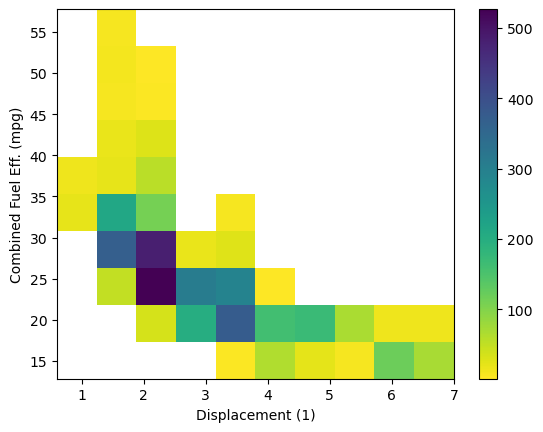

In [48]:
plt.hist2d(data=fuel_econ, x='displ', y='comb', cmin=0.5, cmap='viridis_r')
plt.colorbar()
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

Specify bin edges

Text(0, 0.5, 'Combined Fuel Eff. (mpg)')

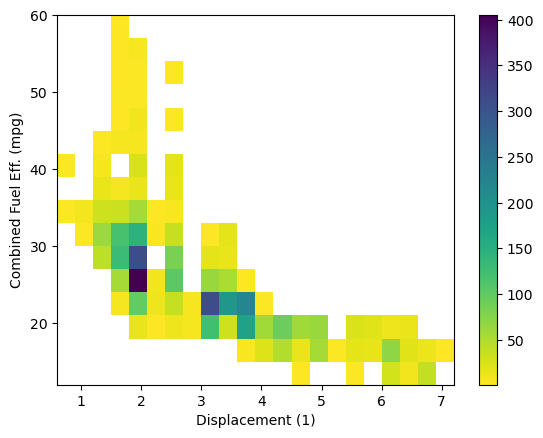

In [49]:
bins_x = np.arange(0.6, 7 + 0.3, 0.3)
bins_y = np.arange(12, 58 + 3, 3)

plt.hist2d(data=fuel_econ, x='displ', y='comb', cmin=0.5, cmap='viridis_r', bins=[bins_x,bins_y])
plt.colorbar()
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

Adding annotatio on each cell using pyplot.text() func

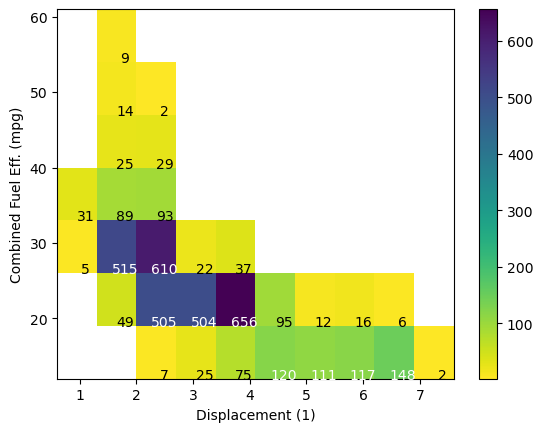

In [50]:
bins_x = np.arange(0.6, 7 + 0.7, 0.7)
bins_y = np.arange(12, 58 + 7, 7)

h2d = plt.hist2d(data=fuel_econ, x='displ', y='comb', cmin=0.5, cmap='viridis_r', bins=[bins_x, bins_y])

plt.colorbar()
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

counts = h2d[0]

for i in range(counts.shape[0]):
    for j in range(counts.shape[1]):
        c = counts[i,j]
        if c >= 100:
            plt.text(bins_x[i] + 0.5, bins_y[j] + 0.5, int(c), ha='center', va='center', color='white')
        elif c > 0:
            plt.text(bins_x[i] + 0.5, bins_y[j] + 0.5, int(c), ha='center', va='center', color='black')

#### Violin Plots

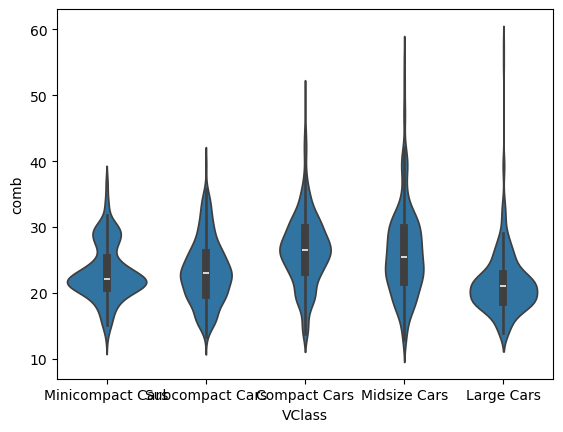

In [51]:
sedan_classes = ['Minicompact Cars', 'Subcompact Cars', 'Compact Cars', 'Midsize Cars', 'Large Cars']

vclasses = pd.api.types.CategoricalDtype(ordered=True, categories=sedan_classes)

fuel_econ['VClass'] = fuel_econ['VClass'].astype(vclasses);

sb.violinplot(data=fuel_econ, x='VClass', y='comb');

Violin plot without datapoints in the violin interior

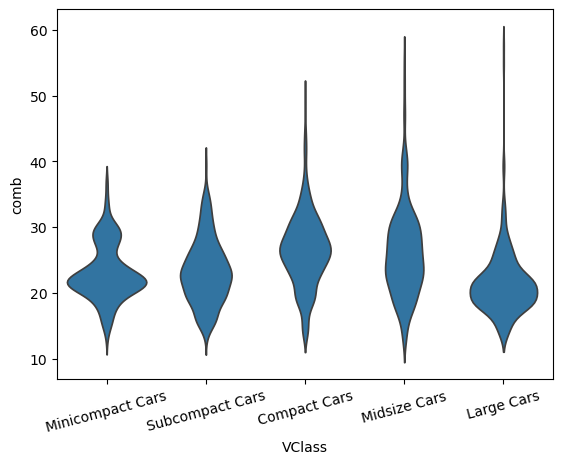

In [52]:
base_color = sb.color_palette()[0]

# The "inner" argument represents the datapoints in the violin interior. 
# It can take any value from {“box”, “quartile”, “point”, “stick”, None}
# If "box", it draws a miniature boxplot. 
sb.violinplot(data=fuel_econ, x='VClass', y='comb', color=base_color, inner=None)
plt.xticks(rotation=15);

Variation

<Axes: xlabel='comb', ylabel='VClass'>

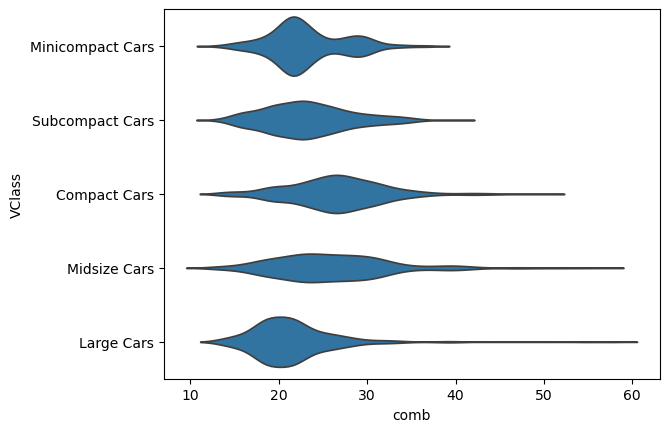

In [53]:
sb.violinplot(data=fuel_econ, y='VClass', x='comb', color=base_color, inner=None)

#### Box plots

(6.966470319355816, 63.09321945242605)

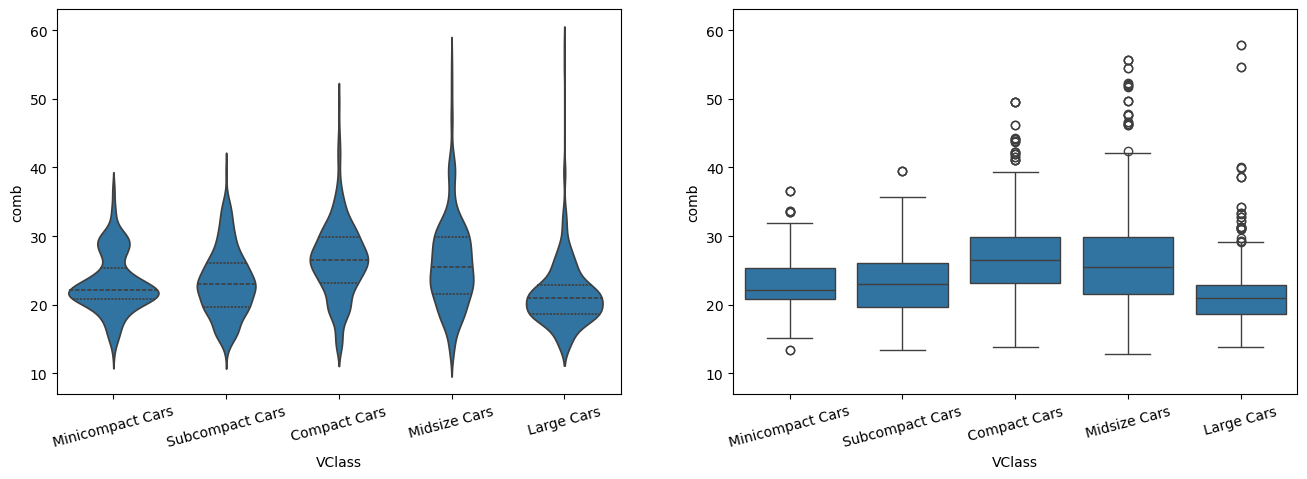

In [54]:
vclasses = pd.api.types.CategoricalDtype(ordered=True, categories=sedan_classes)

fuel_econ['VClass'] = fuel_econ['VClass'].astype(vclasses);

plt.figure(figsize = [16, 5])
base_color = sb.color_palette()[0]

plt.subplot(1, 2, 1)
ax1 = sb.violinplot(data=fuel_econ, x='VClass', y='comb', color=base_color, inner='quartile')
plt.xticks(rotation=15);

plt.subplot(1, 2, 2)
sb.boxplot(data=fuel_econ, x='VClass', y='comb', color=base_color)
plt.xticks(rotation=15);
plt.ylim(ax1.get_ylim())

Variation

<Axes: xlabel='comb', ylabel='VClass'>

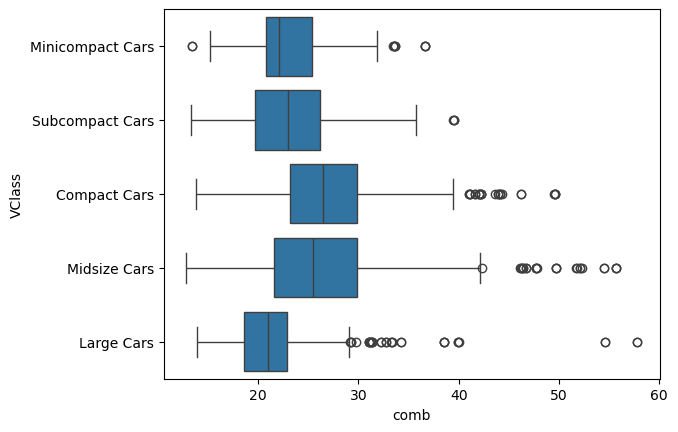

In [55]:
sb.boxplot(data=fuel_econ, y='VClass', x='comb', color=base_color)

Violin plot with quartile information in the middle

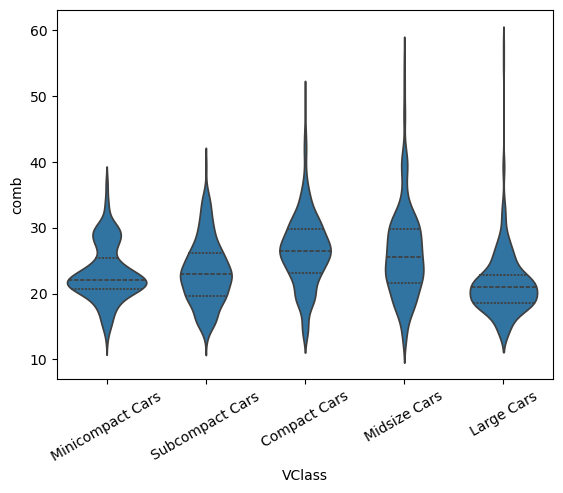

In [56]:
base_color = sb.color_palette()[0]
sb.violinplot(data=fuel_econ, x='VClass', y='comb', color=base_color, inner='quartile')
plt.xticks(rotation=30);

#### Clustered Bar Charts

      id        make           model  year           VClass  \
0  32204      Nissan            GT-R  2013  Subcompact Cars   
1  32205  Volkswagen              CC  2013     Compact Cars   
2  32206  Volkswagen              CC  2013     Compact Cars   
3  32207  Volkswagen      CC 4motion  2013     Compact Cars   
4  32208   Chevrolet  Malibu eAssist  2013     Midsize Cars   

               drive              trans          fuelType  cylinders  displ  \
0    All-Wheel Drive    Automatic (AM6)  Premium Gasoline          6    3.8   
1  Front-Wheel Drive  Automatic (AM-S6)  Premium Gasoline          4    2.0   
2  Front-Wheel Drive     Automatic (S6)  Premium Gasoline          6    3.6   
3    All-Wheel Drive     Automatic (S6)  Premium Gasoline          6    3.6   
4  Front-Wheel Drive     Automatic (S6)  Regular Gasoline          4    2.4   

   ...  pv4     city    UCity  highway  UHighway     comb  co2  feScore  \
0  ...    0  16.4596  20.2988  22.5568   30.1798  18.7389  471        4

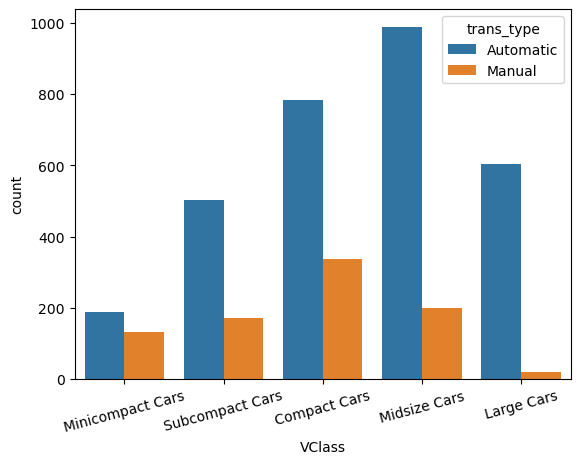

In [57]:
fuel_econ['trans_type'] = fuel_econ['trans'].apply(lambda x: x.split()[0])
print(fuel_econ.head())

sb.countplot(data=fuel_econ, x='VClass', hue='trans_type')
plt.xticks(rotation=15)
plt.show()

Alternative Approach - Plot a Heat Map between two qualitative variables

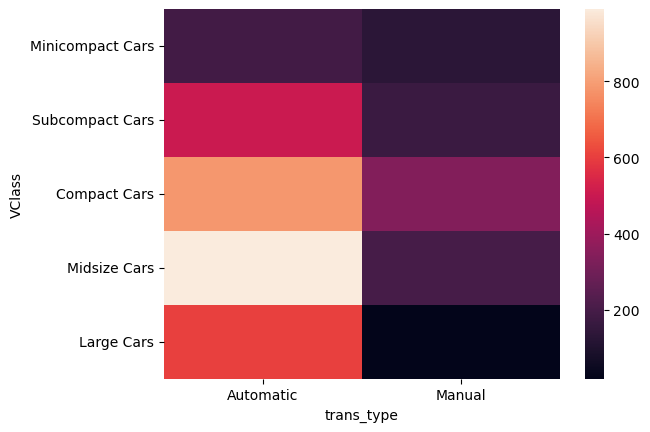

In [58]:
ct_counts = fuel_econ.groupby(['VClass', 'trans_type']).size()
ct_counts = ct_counts.reset_index(name='count')
ct_counts = ct_counts.pivot(index='VClass', columns='trans_type', values='count')

sb.heatmap(ct_counts)
plt.show()

Variation

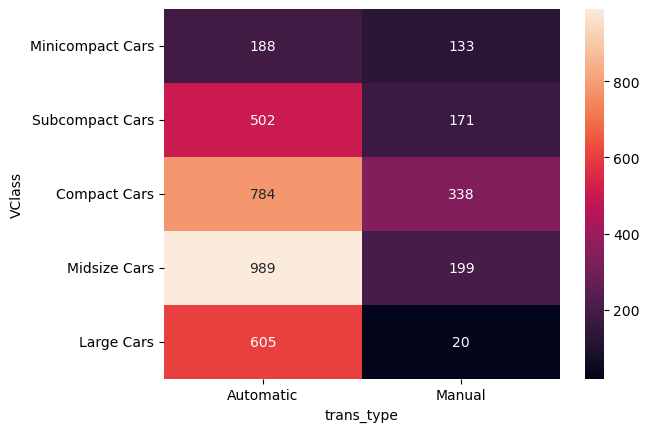

In [59]:
sb.heatmap(ct_counts, annot=True, fmt='d')
plt.show()

#### Faceting

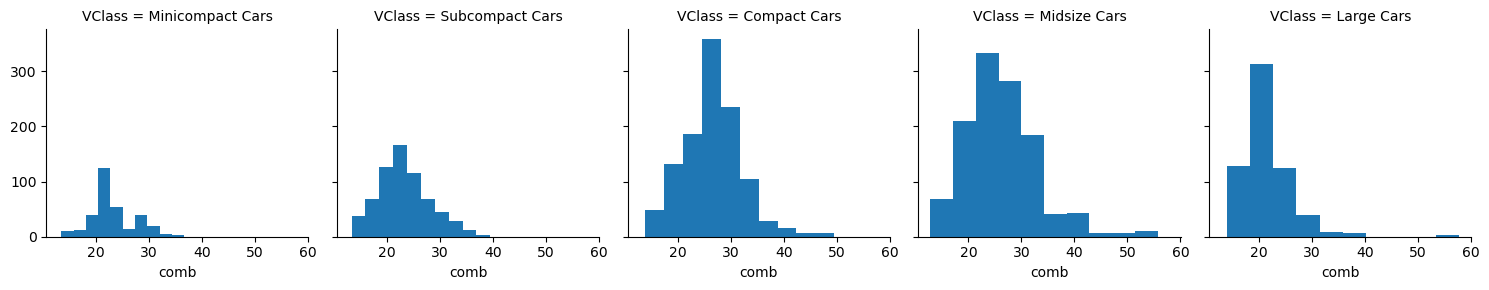

In [62]:
# Convert the "VClass" column from a plain object type into an ordered categorical type
sedan_classes = ['Minicompact Cars', 'Subcompact Cars', 'Compact Cars', 'Midsize Cars', 'Large Cars']
vclasses = pd.api.types.CategoricalDtype(ordered=True, categories=sedan_classes)
fuel_econ['VClass'] = fuel_econ['VClass'].astype(vclasses);

g = sb.FacetGrid(data = fuel_econ, col = 'VClass')
g.map(plt.hist, "comb")
plt.show()

#### Adaptation of Univariate Plots

Text(0, 0.5, 'Avg. Combined Fuel Efficiency (mpg)')

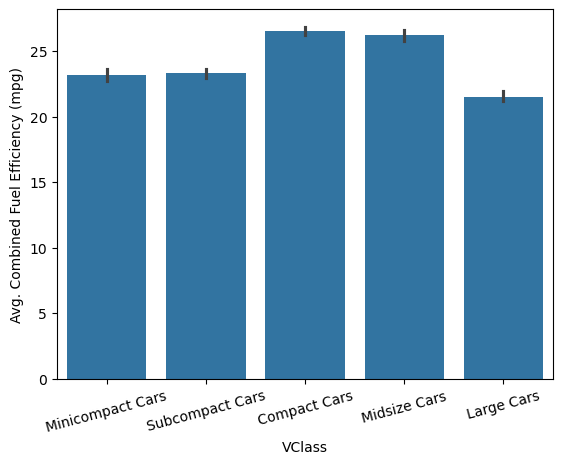

In [63]:
base_color = sb.color_palette()[0]
sb.barplot(data=fuel_econ, x='VClass', y='comb', color=base_color)
plt.xticks(rotation=15);
plt.ylabel('Avg. Combined Fuel Efficiency (mpg)')

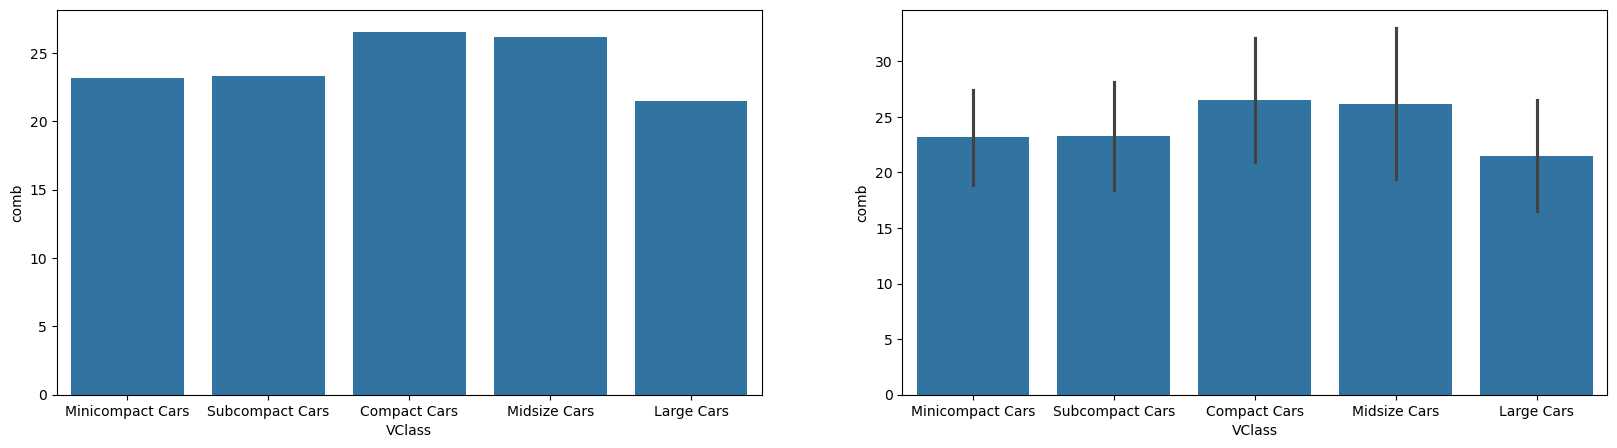

In [66]:
plt.figure(figsize=[20,5])

plt.subplot(1,2,1)
sb.barplot(data=fuel_econ, x='VClass', y='comb', color=base_color, err_kws={'linewidth': 0})

plt.subplot(1,2,2)
sb.barplot(data=fuel_econ, x='VClass', y='comb', color=base_color, errorbar='sd')

plt.show()

Variation

C:\Users\<user>\AppData\Local\Temp\ipykernel_24056\4291305413.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sb.pointplot(data=fuel_econ, x='VClass', y='comb', color=base_color, ci='sd', linestyles="")


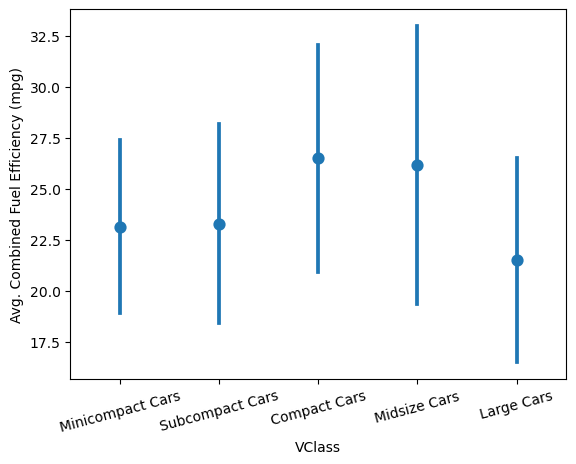

In [68]:
sb.pointplot(data=fuel_econ, x='VClass', y='comb', color=base_color, ci='sd', linestyles="")
plt.xticks(rotation=15);
plt.ylabel('Avg. Combined Fuel Efficiency (mpg)')
plt.show()

#### Comparing

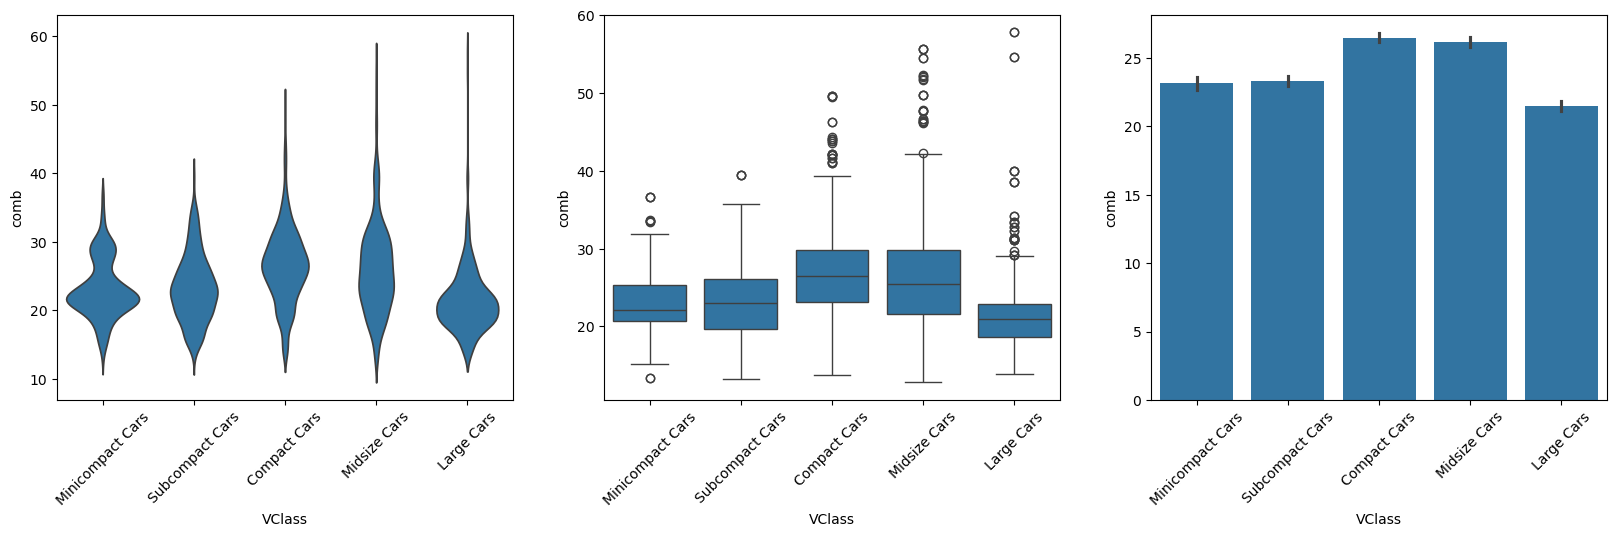

In [69]:
plt.figure(figsize = [20, 5])
base_color = sb.color_palette()[0]

plt.subplot(1, 3, 1)
sb.violinplot(data=fuel_econ, x='VClass', y='comb', inner=None,
              color=base_color)
plt.xticks(rotation = 45);

plt.subplot(1, 3, 2)
sb.boxplot(data=fuel_econ, x='VClass', y='comb', color=base_color)
plt.xticks(rotation = 45);

plt.subplot(1, 3, 3)
sb.barplot(data=fuel_econ, x='VClass', y='comb', color=base_color)
plt.xticks(rotation = 45);

plt.show()

#### Line plots

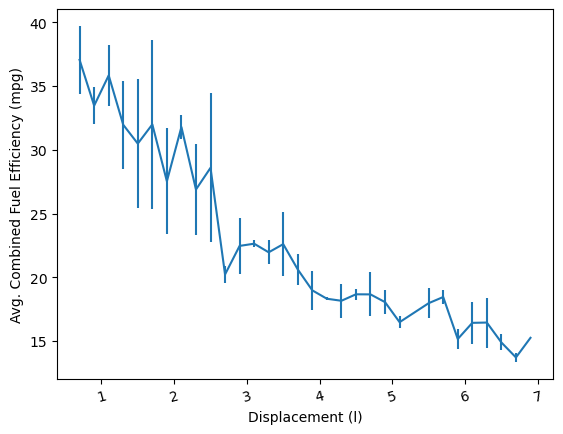

In [72]:
bin_edges = np.arange(0.6, 7+0.2, 0.2)

displ_binned = pd.cut(fuel_econ['displ'], bin_edges, include_lowest = True)
comb_mean = fuel_econ['comb'].groupby(displ_binned).mean()
comb_std = fuel_econ['comb'].groupby(displ_binned).std()

# Extract bin centers from the actual grouped data (only bins with data)
bin_centers = [interval.mid for interval in comb_mean.index]

plt.errorbar(x=bin_centers, y=comb_mean, yerr=comb_std)
plt.xlabel('Displacement (l)')
plt.xticks(rotation=15);
plt.ylabel('Avg. Combined Fuel Efficiency (mpg)');

Variations

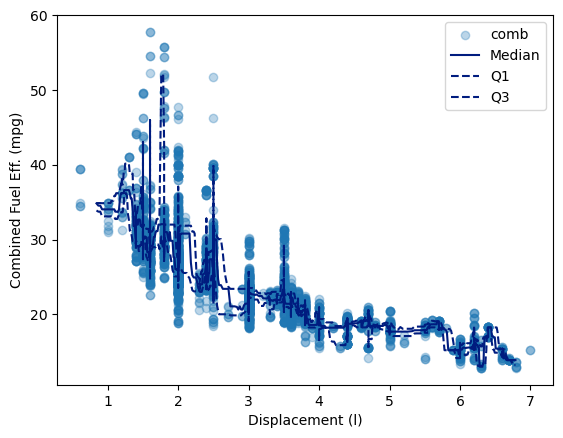

In [77]:
# Sort by displacement and select only numeric columns for rolling window
df_window = fuel_econ.sort_values('displ')[['displ', 'comb']].rolling(15)
x_winmean = df_window.mean()['displ']
y_median = df_window.median()['comb']
y_q1 = df_window.quantile(.25)['comb']
y_q3 = df_window.quantile(.75)['comb']

base_color = sb.color_palette()[0]
line_color = sb.color_palette('dark')[0]
plt.scatter(data = fuel_econ, x = 'displ', y = 'comb', alpha=0.3)
plt.plot(x_winmean, y_median, c = line_color, label='Median')
plt.plot(x_winmean, y_q1, c = line_color, linestyle = '--', label='Q1')
plt.plot(x_winmean, y_q3, c = line_color, linestyle = '--', label='Q3')

plt.xlabel('Displacement (l)')
plt.ylabel('Combined Fuel Eff. (mpg)')
plt.legend()
plt.show()

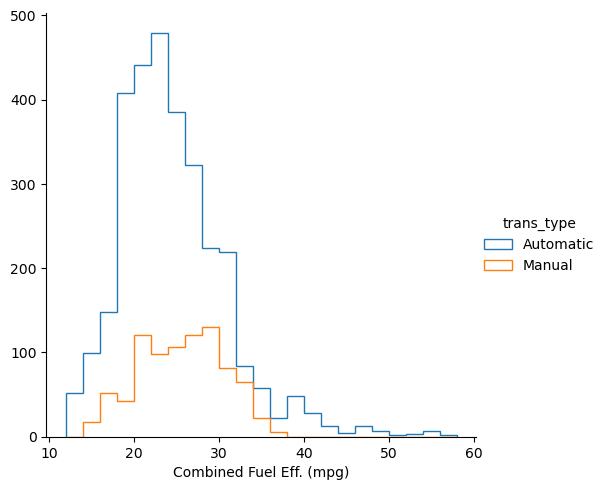

In [78]:
bin_edges = np.arange(12, fuel_econ['comb'].max()+2, 2)
g = sb.FacetGrid(data = fuel_econ, hue = 'trans_type', height = 5)
g.map(plt.hist, "comb", bins = bin_edges, histtype = 'step')
g.add_legend()
plt.xlabel('Combined Fuel Eff. (mpg)')
plt.show()

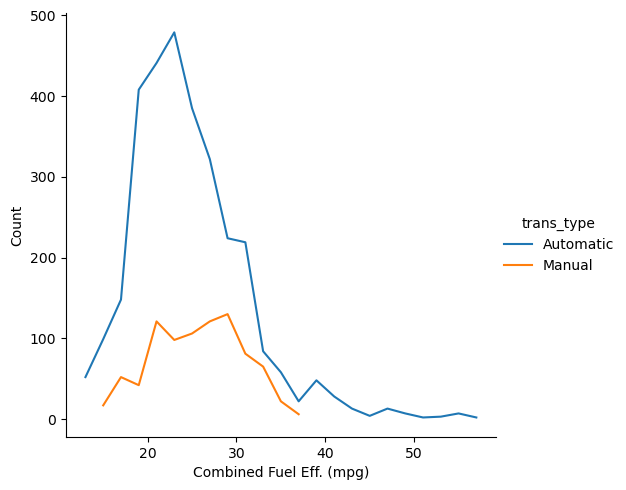

In [80]:
def freq_poly(x, bins = 10, **kwargs):
    """ Custom frequency polygon / line plot code. """
    # set bin edges if none or int specified
    if type(bins) == int:
        bins = np.linspace(x.min(), x.max(), bins+1)
    
    # compute counts
    data_bins = pd.cut(x, bins, right = False,
                       include_lowest = True)
    counts = x.groupby(data_bins).count()
    
    # Extract bin centers from the actual grouped data (only bins with data)
    bin_centers = [interval.mid for interval in counts.index]
    
    # create plot
    plt.plot(bin_centers, counts, **kwargs)
    
bin_edges = np.arange(12, fuel_econ['comb'].max()+2, 2)
g = sb.FacetGrid(data = fuel_econ, hue = 'trans_type', height = 5)
g.map(freq_poly, "comb", bins = bin_edges)
g.add_legend()
plt.xlabel('Combined Fuel Eff. (mpg)')
plt.ylabel('Count')
plt.show()